# **Basic queueing system-1**

In [ ]:
!pip install simpy

In [ ]:
#single server queue
import simpy, random

def customer(env, name, server):
    t = env.now
    print(name, "arrives at", t)

    with server.request() as req:
        yield req
        print(name, "waits", env.now - t)

        yield env.timeout(random.expovariate(1))
        print(name, "leaves at", env.now)

def setup(env):
    server = simpy.Resource(env, capacity=1)

    for i in range(5):
        env.process(customer(env, f"Cust {i}", server))
        yield env.timeout(random.expovariate(0.5))

env = simpy.Environment()
env.process(setup(env))
env.run(until=20)

Cust 0 arrives at 0
Cust 0 waits 0
Cust 1 arrives at 0.5687530092264403
Cust 0 leaves at 1.6092045894595317
Cust 1 waits 1.0404515802330914
Cust 1 leaves at 1.6545206570019215
Cust 2 arrives at 3.7393285682735913
Cust 2 waits 0.0
Cust 3 arrives at 3.847865039245943
Cust 4 arrives at 4.1289603107792665
Cust 2 leaves at 5.193728936071446
Cust 3 waits 1.3458638968255032
Cust 3 leaves at 6.90092473192272
Cust 4 waits 2.771964421143453
Cust 4 leaves at 10.067750587253084


In [ ]:
#track average waiting time & utilization
import simpy, random

wait = []

def customer(env, server):
    t = env.now
    with server.request() as req:
        yield req
        wait.append(env.now - t)
        yield env.timeout(random.expovariate(1))

def setup(env, server):
    for i in range(10):
        env.process(customer(env, server))
        yield env.timeout(random.expovariate(0.5))

env = simpy.Environment()
server = simpy.Resource(env, capacity=1)
env.process(setup(env, server))
env.run(until=30)

print("Average waiting time:", round(sum(wait)/len(wait), 2))

Average waiting time: 5.17


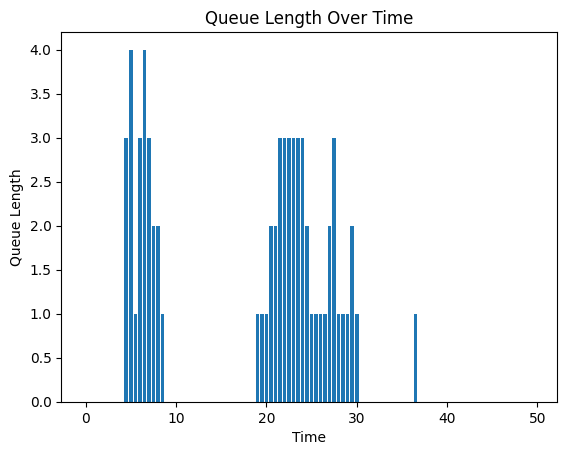

In [ ]:
#simulating busy period & queue length tracking
import simpy, random
import matplotlib.pyplot as plt

q, t = [], []

def monitor(env, s):
    while True:
        q.append(len(s.queue))
        t.append(env.now)
        yield env.timeout(0.5)

def customer(env, s):
    with s.request() as r:
        yield r
        yield env.timeout(random.expovariate(1))

def setup(env, s):
    for i in range(30):
        env.process(customer(env, s))
        yield env.timeout(random.expovariate(0.7))

env = simpy.Environment()
s = simpy.Resource(env, capacity=1)
env.process(setup(env, s))
env.process(monitor(env, s))
env.run(until=50)

plt.bar(t, q, width=0.4)
plt.xlabel("Time")
plt.ylabel("Queue Length")
plt.title("Queue Length Over Time")
plt.show()

# **Inventory management-2**

In [ ]:
#USB drives
class Inventory:
    def __init__(self, name, qty):
        self.name = name
        self.qty = qty

    def sell(self, amount):
        if self.qty >= amount:
            self.qty -= amount
            print("Sold:", amount)
        else:
            print("Not enough stock")

        if self.qty < 10:
            self.qty += 30
            print("Restocked")

        print("Remaining stock:", self.qty)

item = Inventory("USB Drives", 20)

item.sell(6)
item.sell(8)
item.sell(5)

print("Final stock:", item.qty)

Sold: 6
Remaining stock: 14
Sold: 8
Restocked
Remaining stock: 36
Sold: 5
Remaining stock: 31
Final stock: 31


In [ ]:
#milk packet
import random
from collections import deque

class Inventory:
    def __init__(self):
        self.stock = deque()
        self.waste = 0

    def add(self):
        self.stock.append([10, 3])

    def sell(self, n):
        while n > 0 and self.stock:
            q, d = self.stock.popleft()
            sold = min(q, n)
            n -= sold
            if q > sold:
                self.stock.appendleft([q-sold, d])

    def update(self):
        temp = deque()
        for q, d in self.stock:
            d -= 1
            if d == 0:
                self.waste += q
            else:
                temp.append([q, d])
        self.stock = temp

    def report(self, day):
        print("Day:", day)
        print("Stock:", sum(q for q, d in self.stock))
        print("Waste:", self.waste)

item = Inventory()

for day in range(1, 6):
    item.add()
    item.sell(random.randint(8, 12))
    item.update()
    item.report(day)

Day: 1
Stock: 0
Waste: 0
Day: 2
Stock: 1
Waste: 0
Day: 3
Stock: 2
Waste: 0
Day: 4
Stock: 2
Waste: 0
Day: 5
Stock: 1
Waste: 0


In [ ]:
#laptop,headphone,mice
class Inventory:
    def __init__(self, name, qty, level, restock, price):
        self.name = name
        self.qty = qty
        self.level = level
        self.restock = restock
        self.price = price
        self.sales = 0

    def sell(self, n):
        if self.qty >= n:
            self.qty -= n
            self.sales += n * self.price
            print("Sold:", n, self.name)
        else:
            print("Not enough stock")

        if self.qty <= self.level:
            self.qty += self.restock
            print("Restocked:", self.name)

    def report(self):
        print(self.name, "Stock:", self.qty, "Sales: ₹", self.sales)

items = [
    Inventory("Laptops", 5, 2, 3, 50000),
    Inventory("Headphones", 10, 4, 10, 1500),
    Inventory("Mice", 8, 3, 7, 500)
]

items[0].sell(3)
items[1].sell(7)
items[2].sell(6)

print("\nFinal Report")
for item in items:
    item.report()

Sold: 3 Laptops
Restocked: Laptops
Sold: 7 Headphones
Restocked: Headphones
Sold: 6 Mice
Restocked: Mice

Final Report
Laptops Stock: 5 Sales: ₹ 150000
Headphones Stock: 13 Sales: ₹ 10500
Mice Stock: 9 Sales: ₹ 3000


# **Discrete vs continuous-3**

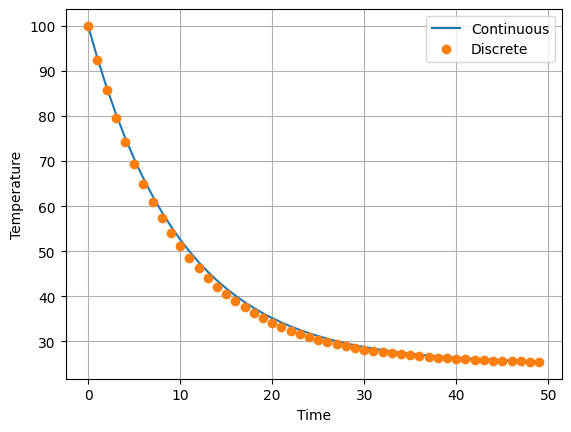

In [ ]:
#Newtons law of cooling
import numpy as np
import matplotlib.pyplot as plt

T0, Tr, k, dt = 100, 25, 0.1, 1
t = np.arange(0, 50, dt)

# Continuous model
Tc = Tr + (T0-Tr) * np.exp(-k*t)

# Discrete model (Euler)
Td = [T0]
for i in range(len(t)-1):
    Td.append(Td[-1] - k*(Td[-1]-Tr)*dt)

# Plot
plt.plot(t, Tc, label="Continuous")
plt.plot(t, Td, 'o', label="Discrete")
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.legend()
plt.grid()
plt.show()

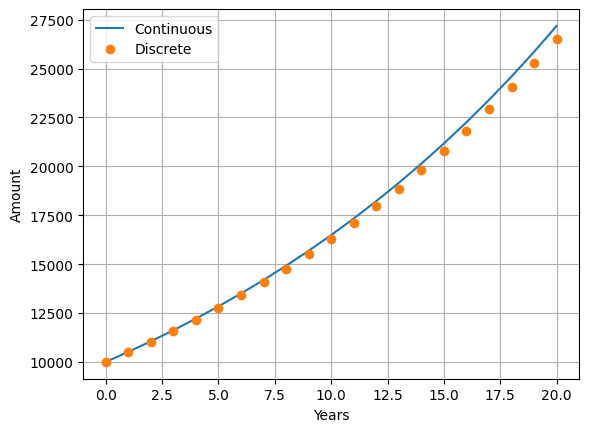

In [ ]:
#Interest
import numpy as np
import matplotlib.pyplot as plt

P, r = 10000, 0.05
t = np.arange(0, 21)

# Continuous model
A1 = P * np.exp(r*t)

# Discrete model
A2 = [P]
for i in range(20):
    A2.append(A2[-1] * (1+r))

# Plot
plt.plot(t, A1, label="Continuous")
plt.plot(t, A2, 'o', label="Discrete")
plt.xlabel("Years")
plt.ylabel("Amount")
plt.legend()
plt.grid()
plt.show()

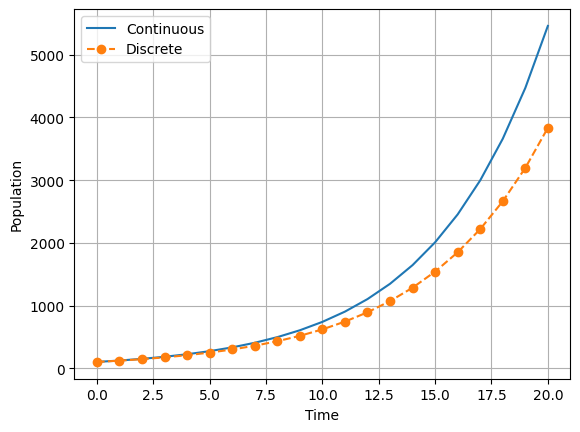

In [ ]:
#bacterial growth rate
import numpy as np
import matplotlib.pyplot as plt

P, r = 100, 0.2
t = np.arange(21)

# Continuous growth
P1 = P * np.exp(r*t)

# Discrete growth
P2 = [P]
for i in range(20):
    P2.append(P2[-1] * (1+r))

# Plot
plt.plot(t, P1, label="Continuous")
plt.plot(t, P2, 'o--', label="Discrete")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()

# **components of system-4**

In [ ]:
#ordering food
def food_order():
    menu = {"Pizza": 200, "Burger": 100, "Pasta": 150}

    print(menu)
    item = input("Enter item: ")
    qty = int(input("Enter quantity: "))

    if item in menu:
        print("Total Bill: ₹", menu[item] * qty)
    else:
        print("Item not available")

food_order()

{'Pizza': 200, 'Burger': 100, 'Pasta': 150}
Enter item: Pizza
Enter quantity: 4
Total Bill: ₹ 800


In [ ]:
#vending machine
def vending():
    items = {"Chips": 20, "Soda": 30, "Chocolate": 25}

    print(items)
    choice = input("Select item: ")
    money = int(input("Enter money: "))

    if choice not in items:
        print("Invalid selection")
    elif money < items[choice]:
        print("Not enough money")
    else:
        print("Dispensed:", choice)
        print("Change: ₹", money - items[choice])

vending()

{'Chips': 20, 'Soda': 30, 'Chocolate': 25}
Select item: Soda
Enter money: 70
Dispensed: Soda
Change: ₹ 40


In [ ]:
#grading system
def grading():
    m = int(input("Enter marks: "))

    if m >= 90:
        g = "A"
    elif m >= 75:
        g = "B"
    elif m >= 50:
        g = "C"
    else:
        g = "F"

    print("Grade:", g)

grading()

Enter marks: 80
Grade: B


In [ ]:
#hospital queue system
from collections import deque

q = deque()

for i in range(3):
    q.append(input("Enter patient name: "))

while q:
    print("Treating:", q.popleft())

Enter patient name: AAA
Enter patient name: BBB
Enter patient name: CCC
Treating: AAA
Treating: BBB
Treating: CCC


In [ ]:
#shop system
def inventory():
    items = {"Book": [100, 10], "Pen": [10, 20], "Bag": [500, 5]}

    print(items)
    name = input("Enter item: ")
    qty = int(input("Enter quantity: "))

    if name not in items:
        print("Item not found")
    elif qty > items[name][1]:
        print("Not enough stock")
    else:
        total = qty * items[name][0]
        items[name][1] -= qty
        print("Total: ₹", total)
        print("Remaining stock:", items[name][1])

inventory()

{'Book': [100, 10], 'Pen': [10, 20], 'Bag': [500, 5]}
Enter item: Pen
Enter quantity: 5
Total: ₹ 50
Remaining stock: 15


In [ ]:
#Loan system
def emi():
    p = float(input("Loan amount: "))
    r = float(input("Interest rate: ")) / 1200
    n = int(input("Years: ")) * 12

    e = p*r*(1+r)**n / ((1+r)**n-1)
    print("Monthly EMI: ₹", round(e, 2))

emi()

Loan amount: 50000
Interest rate: 6
Years: 2
Monthly EMI: ₹ 2216.03


# **Poisson arrival process-5**

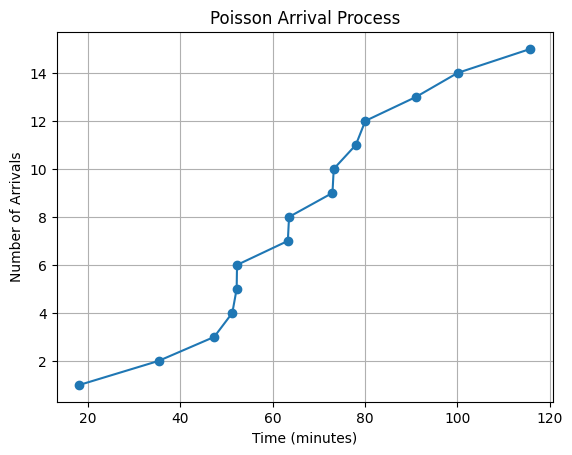

Total arrivals: 15


In [ ]:
#simulate poisson arrivals in 1hr
import numpy as np
import matplotlib.pyplot as plt

t, T, lam = 0, 120, 4/30
a = []

while t < T:
    t += np.random.exponential(1/lam)
    if t < T:
        a.append(t)

plt.plot(a, range(1, len(a)+1), 'o-')
plt.xlabel("Time (minutes)")
plt.ylabel("Number of Arrivals")
plt.title("Poisson Arrival Process")
plt.grid()
plt.show()

print("Total arrivals:", len(a))

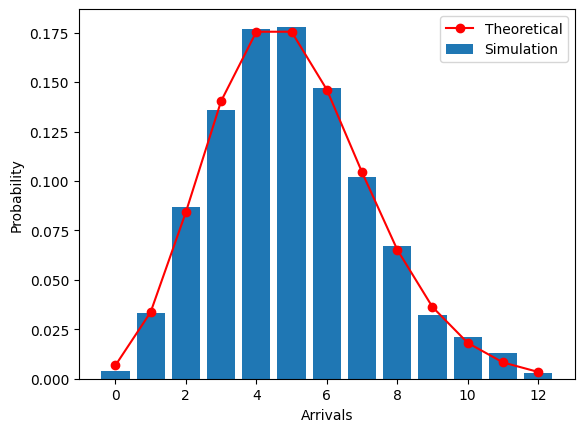

In [ ]:
#compare simulation with theoretical poisson distribution
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

lam = 5
a = np.random.poisson(lam, 1000)

x, c = np.unique(a, return_counts=True)

plt.bar(x, c/1000, label="Simulation")
plt.plot(x, poisson.pmf(x, lam), 'ro-', label="Theoretical")
plt.xlabel("Arrivals")
plt.ylabel("Probability")
plt.legend()
plt.show()

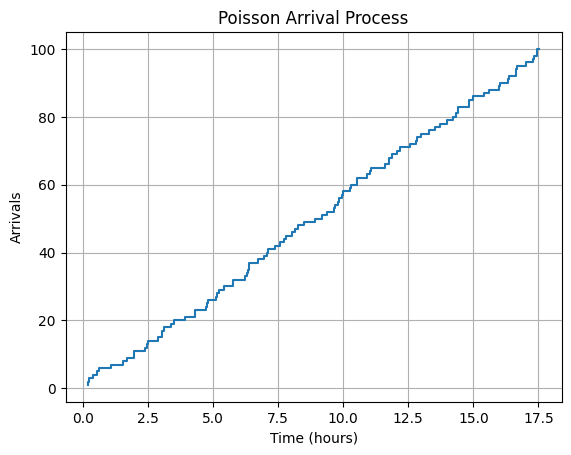

Average: 0.1752659651707164
Theoretical mean: 0.16666666666666666


In [ ]:
#Average waiting time between arrivals
import numpy as np
import matplotlib.pyplot as plt

lam = 6
n = 100

a = np.random.exponential(1/lam, n)
t = np.cumsum(a)

plt.step(t, range(1, n+1))
plt.xlabel("Time (hours)")
plt.ylabel("Arrivals")
plt.title("Poisson Arrival Process")
plt.grid()
plt.show()

print("Average:", a.mean())
print("Theoretical mean:", 1/lam)

# **Continuous distribution-normal & exponential-6**

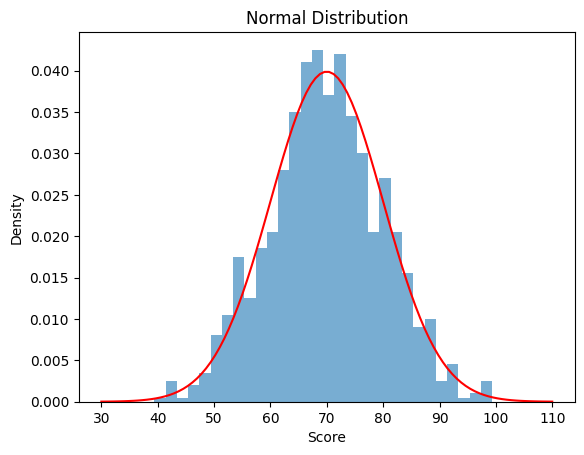

Mean: 69.87312910110401
Standard Deviation: 10.07648810263614


In [ ]:
#Simulating Exam Scores (Normal Distribution)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu, sigma = 70, 10
data = np.random.normal(mu, sigma, 1000)

plt.hist(data, bins=30, density=True, alpha=0.6)

x = np.linspace(30, 110, 100)
plt.plot(x, norm.pdf(x, mu, sigma), 'r')

plt.xlabel("Score")
plt.ylabel("Density")
plt.title("Normal Distribution")
plt.show()

print("Mean:", np.mean(data))
print("Standard Deviation:", np.std(data))

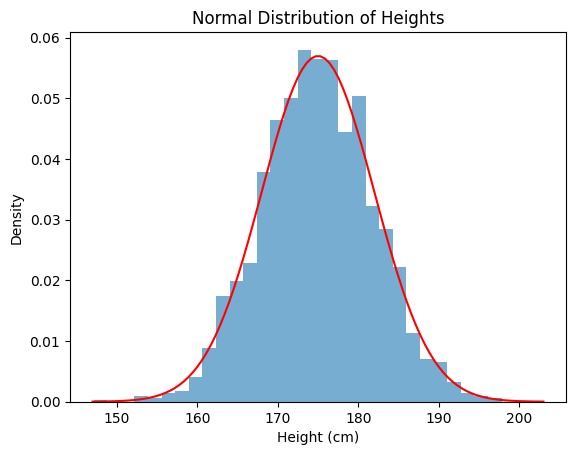

Mean: 174.9637421307027
Standard Deviation: 6.927146274500759


In [ ]:
# Heights of Adult Males (Normal Distribution)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu, sigma = 175, 7
heights = np.random.normal(mu, sigma, 2000)

plt.hist(heights, bins=30, density=True, alpha=0.6)

x = np.linspace(mu-4*sigma, mu+4*sigma, 100)
plt.plot(x, norm.pdf(x, mu, sigma), 'r')

plt.title("Normal Distribution of Heights")
plt.xlabel("Height (cm)")
plt.ylabel("Density")
plt.show()

print("Mean:", np.mean(heights))
print("Standard Deviation:", np.std(heights))

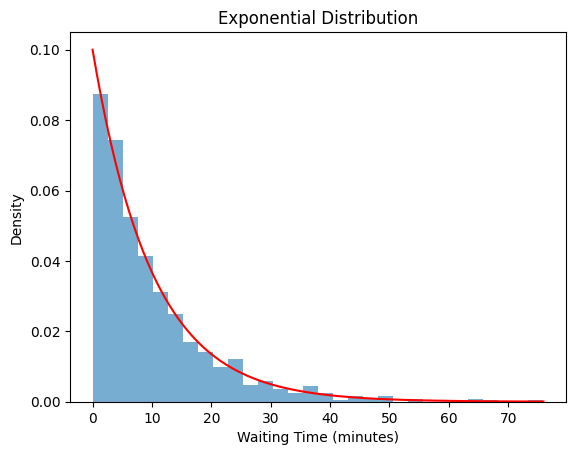

Sample mean: 9.920530154125982
Theoretical mean: 10


In [ ]:
#Taxi Waiting Times (Exponential Distribution)
import numpy as np
import matplotlib.pyplot as plt

mean = 10
lam = 1 / mean
data = np.random.exponential(mean, 1000)

plt.hist(data, bins=30, density=True, alpha=0.6)

x = np.linspace(0, max(data), 100)
plt.plot(x, lam * np.exp(-lam*x), 'r')

plt.title("Exponential Distribution")
plt.xlabel("Waiting Time (minutes)")
plt.ylabel("Density")
plt.show()

print("Sample mean:", np.mean(data))
print("Theoretical mean:", mean)

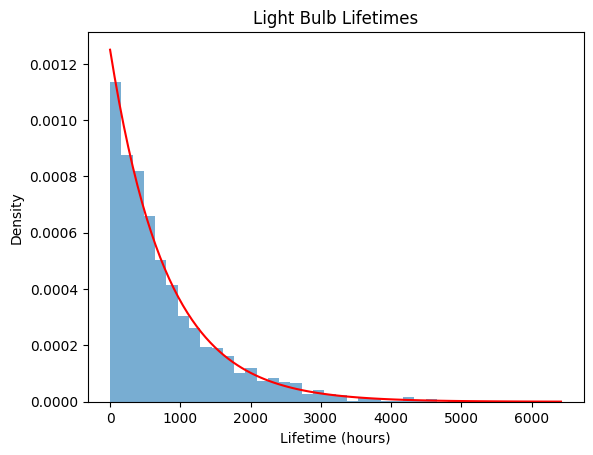

Sample mean: 799.6327158402601
Theoretical mean: 800


In [ ]:
#Lifetime of Light Bulbs (Exponential Distribution)
import numpy as np
import matplotlib.pyplot as plt

mean = 800
lam = 1 / mean
data = np.random.exponential(mean, 2000)

plt.hist(data, bins=40, density=True, alpha=0.6)

x = np.linspace(0, max(data), 100)
plt.plot(x, lam * np.exp(-lam*x), 'r')

plt.title("Light Bulb Lifetimes")
plt.xlabel("Lifetime (hours)")
plt.ylabel("Density")
plt.show()

print("Sample mean:", np.mean(data))
print("Theoretical mean:", mean)

# **M/M/1 & M/M/C-7**

In [ ]:
#Problem 1 & 2: Single Server Queue Simulation (M/M/1 Model)
import numpy as np

lam, mu = 2, 3
N = 10000

arrival = np.cumsum(np.random.exponential(1/lam, N))
service = np.random.exponential(1/mu, N)

finish = 0
wait = []
system = []

for i in range(N):
    start = max(arrival[i], finish)
    finish = start + service[i]

    wait.append(start - arrival[i])
    system.append(finish - arrival[i])

print("Average waiting time (Wq):", np.mean(wait))
print("Average time in system (W):", np.mean(system))

Average waiting time (Wq): 0.6024221807851949
Average time in system (W): 0.9328962428008999


In [ ]:
#Multi-Server Call Center Simulation (M/M/c Model using Heap)
import numpy as np
import heapq

lam, mu = 10, 6
c, N = 2, 5000

arrival = np.cumsum(np.random.exponential(1/lam, N))
service = np.random.exponential(1/mu, N)

servers = [0] * c
wait = []
system = []

for i in range(N):
    available = heapq.heappop(servers)
    start = max(arrival[i], available)
    finish = start + service[i]

    wait.append(start - arrival[i])
    system.append(finish - arrival[i])

    heapq.heappush(servers, finish)

print("Average waiting time (Wq):", np.mean(wait))
print("Average time in system (W):", np.mean(system))

Average waiting time (Wq): 0.3057744993961643
Average time in system (W): 0.4697421265148292


In [ ]:
#Hybrid Multi-Server Comparison (Analytical Erlang-C vs Simulation)
import numpy as np
import heapq
import math

lam, mu, c, N = 15, 7, 3, 5000

# Analytical calculation (Erlang-C)
rho = lam / (c * mu)

s = sum((lam/mu)**n / math.factorial(n) for n in range(c))
p = (lam/mu)**c / (math.factorial(c) * (1-rho))

P0 = 1 / (s + p)
P_wait = p * P0

Lq = P_wait * lam / (c*mu - lam)
Wq = Lq / lam
W = Wq + 1/mu

print("Analytical Wq:", round(Wq, 4))
print("Analytical W:", round(W, 4))

# Simulation
np.random.seed(42)

arrival = np.cumsum(np.random.exponential(1/lam, N))
service = np.random.exponential(1/mu, N)

servers = [0] * c
wait, system = [], []

for i in range(N):
    available = heapq.heappop(servers)
    start = max(arrival[i], available)
    finish = start + service[i]

    wait.append(start - arrival[i])
    system.append(finish - arrival[i])

    heapq.heappush(servers, finish)

print("Simulated Wq:", round(np.mean(wait), 4))
print("Simulated W:", round(np.mean(system), 4))

Analytical Wq: 0.0856
Analytical W: 0.2284
Simulated Wq: 0.0629
Simulated W: 0.2008


# **Test for pseudorandom numbers-8**

In [ ]:
# Chi-square Goodness-of-Fit Test (Uniform Distribution - Fair Die)
import numpy as np
from scipy.stats import chi2

observed = np.array([8, 9, 10, 12, 11, 10])
expected = np.array([10] * 6)

chi = sum((observed - expected)**2 / expected)
df = 5
p = 1 - chi2.cdf(chi, df)

print("Chi-square:", chi)
print("Degrees of freedom:", df)
print("P-value:", p)

if p > 0.05:
    print("Die is fair")
else:
    print("Die is not fair")

Chi-square: 1.0
Degrees of freedom: 5
P-value: 0.9625657732472964
Die is fair


In [ ]:
#Chi-square Test for Independence (Contingency Table)
import numpy as np
from scipy.stats import chi2_contingency

table = np.array([[15, 25], [35, 25]])

chi, p, df, expected = chi2_contingency(table)

print("Chi-square:", chi)
print("Degrees of freedom:", df)
print("P-value:", p)
print("Expected frequencies:\n", expected)

if p > 0.05:
    print("Smoking and exercise are independent")
else:
    print("Smoking and exercise are not independent")

Chi-square: 3.375
Degrees of freedom: 1
P-value: 0.06619257972219346
Expected frequencies:
 [[20. 20.]
 [30. 30.]]
Smoking and exercise are independent


In [ ]:
#Chi-square Goodness-of-Fit (Non-Uniform Proportional Claim)
import numpy as np
from scipy.stats import chi2

observed = np.array([18, 35, 62, 85])
expected = np.array([20, 40, 60, 80])

chi = sum((observed - expected)**2 / expected)
df = 3
p = 1 - chi2.cdf(chi, df)

print("Chi-square:", chi)
print("Degrees of freedom:", df)
print("P-value:", p)

if p > 0.05:
    print("Distribution matches the claim")
else:
    print("Distribution does not match the claim")

Chi-square: 1.2041666666666666
Degrees of freedom: 3
P-value: 0.7520051473152217
Distribution matches the claim


In [ ]:
#One-sample KS test (Uniform Distribution Validation)
import numpy as np
from scipy.stats import kstest

np.random.seed(0)
data = np.random.rand(100)

stat, p = kstest(data, 'uniform')

print("KS Statistic:", stat)
print("P-value:", p)

if p > 0.05:
    print("Data follows Uniform distribution")
else:
    print("Data does not follow Uniform distribution")

KS Statistic: 0.0736727958814345
P-value: 0.6226614157861845
Data follows Uniform distribution


In [ ]:
#One-sample KS test (Normal Distribution Validation)
import numpy as np
from scipy.stats import kstest

np.random.seed(1)
data = np.random.normal(1000, 100, 150)

stat, p = kstest(data, 'norm', args=(1000, 100))

print("KS Statistic:", stat)
print("P-value:", p)

if p > 0.05:
    print("Data follows Normal distribution")
else:
    print("Data does not follow Normal distribution")

KS Statistic: 0.06634234862420318
P-value: 0.5028649024717484
Data follows Normal distribution


In [ ]:
#Two-sample KS test (Comparing Two Sample Distributing Forms)
import numpy as np
from scipy.stats import ks_2samp

np.random.seed(2)
A = np.random.normal(70, 10, 50)
B = np.random.normal(75, 10, 50)

stat, p = ks_2samp(A, B)

print("KS Statistic:", stat)
print("P-value:", p)

if p > 0.05:
    print("Both groups have same distribution")
else:
    print("Both groups have different distributions")

KS Statistic: 0.38
P-value: 0.0013147736033165794
Both groups have different distributions


# **Fit test-9**

Mean: 10.4
Standard Deviation: 1.9849433241279208
KS Statistic: 0.15969127176788744
P-value: 0.6308714140910622
Data follows Normal Distribution


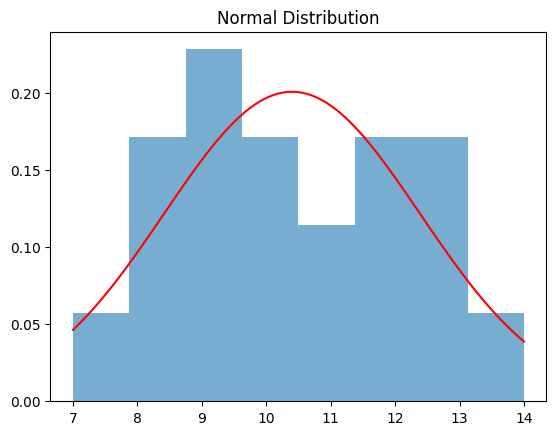

In [ ]:
#Fitting a Normal Distribution (Bank Waiting Times)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, kstest

data = [7, 9, 8, 11, 13, 9, 12, 10, 14, 13,
        8, 9, 12, 10, 11, 13, 10, 9, 8, 12]

mean = np.mean(data)
std = np.std(data)

stat, p = kstest(data, 'norm', args=(mean, std))

print("Mean:", mean)
print("Standard Deviation:", std)
print("KS Statistic:", stat)
print("P-value:", p)

if p > 0.05:
    print("Data follows Normal Distribution")
else:
    print("Data does not follow Normal Distribution")

plt.hist(data, bins=8, density=True, alpha=0.6)
x = np.linspace(min(data), max(data), 100)
plt.plot(x, norm.pdf(x, mean, std), 'r')
plt.title("Normal Distribution")
plt.show()

In [ ]:
#Fitting an Exponential Distribution (Ticket Service Times)
import numpy as np
from scipy.stats import expon, chi2

data = [2.1, 1.9, 3.5, 2.8, 1.7, 3.3, 2.5, 2.0, 3.1, 1.6,
        2.4, 2.9, 1.5, 3.0, 2.6, 2.2, 1.8, 3.4, 2.3, 2.7,
        3.2, 1.9, 2.8, 3.3, 2.1]

lam = 1 / np.mean(data)
bins = np.linspace(min(data), max(data), 6)

obs, _ = np.histogram(data, bins)
exp = len(data) * np.diff(expon.cdf(bins, scale=1/lam))

chi = np.sum((obs-exp)**2 / exp)
df = len(bins) - 2
p = 1 - chi2.cdf(chi, df)

print("Lambda:", round(lam, 4))
print("Chi-square:", round(chi, 4))
print("P-value:", round(p, 4))

if p > 0.05:
    print("Data follows Exponential Distribution")
else:
    print("Data does not follow Exponential Distribution")

Lambda: 0.3994
Chi-square: 50.6867
P-value: 0.0
Data does not follow Exponential Distribution


In [ ]:
#Fitting a Poisson Distribution (Customer Arrivals per Minute)
import numpy as np
from scipy.stats import poisson, chi2

data = [2,3,4,2,1,0,3,2,4,3,2,1,0,4,3,2,1,3,2,4,
        3,2,1,0,3,2,4,2,3,1]

lam = np.mean(data)

values, obs = np.unique(data, return_counts=True)
exp = len(data) * poisson.pmf(values, lam)

chi = np.sum((obs - exp)**2 / exp)
df = len(values) - 2
p = 1 - chi2.cdf(chi, df)

print("Lambda:", round(lam, 2))
print("Chi-square:", round(chi, 4))
print("P-value:", round(p, 4))

if p > 0.05:
    print("Data follows Poisson Distribution")
else:
    print("Data does not follow Poisson Distribution")

Lambda: 2.23
Chi-square: 2.3218
P-value: 0.5083
Data follows Poisson Distribution


# **verification & validation-10**

In [ ]:
#Single-Server Queue (M/M/1 Model) Verification & Validation
import random
import numpy as np

arrival, end, wait = [0], [], []

for i in range(1, 100):
    arrival.append(arrival[-1] + random.expovariate(1/5))

for i in range(100):
    start = max(arrival[i], end[-1] if end else 0)
    finish = start + random.expovariate(1/4)
    end.append(finish)
    wait.append(start - arrival[i])

lam, mu = 1/5, 1/4
Wq = lam / (mu * (mu - lam))

print("Verification:", "Passed" if all(end[i] >= arrival[i] for i in range(100)) else "Failed")
print("Simulation Waiting Time:", round(np.mean(wait), 2))
print("Theory Waiting Time:", round(Wq, 2))

if abs(np.mean(wait) - Wq) / Wq < 0.2:
    print("Validation Passed")
else:
    print("Validation Failed")

Verification: Passed
Simulation Waiting Time: 23.81
Theory Waiting Time: 16.0
Validation Failed


In [ ]:
#Monte Carlo Estimation of \(\pi \)
import random
import math

n = 100000
inside = 0

for i in range(n):
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)

    if x**2 + y**2 <= 1:
        inside += 1

pi = 4 * inside / n

print("Estimated Pi:", round(pi, 5))
print("Actual Pi:", round(math.pi, 5))

if abs(pi - math.pi) / math.pi < 0.02:
    print("Validation Passed")
else:
    print("Validation Failed")

Estimated Pi: 3.14316
Actual Pi: 3.14159
Validation Passed


In [ ]:
#Coin Toss Simulation
import random

n = 10000
heads = 0

for i in range(n):
    if random.choice(['H', 'T']) == 'H':
        heads += 1

prob = heads / n

print("Simulated Probability:", round(prob, 3))
print("Theoretical Probability:", 0.5)

if abs(prob - 0.5) < 0.02:
    print("Validation Passed")
else:
    print("Validation Failed")

Simulated Probability: 0.509
Theoretical Probability: 0.5
Validation Passed
